# Jev_CeNN — Full Encoder: Progressive Two-Window + CeNN, 28 → 10 Active Blocks

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vtavakkoli/TinyCeNN-LM/blob/main/notebooks/Jev_CeNN_AllLayers_3to1_Progressive_Colab.ipynb)

## Your single-group starting point (actual supplied experiment)

The earlier layers **15–17 → 1** experiment reached blind-audit **0.96915 cosine**, **0.000958 NMSE**, **74.17% teacher decision agreement** across 240 DEV decisions, and was **3.18× slower** than the original three-block segment (18.36 ms versus 5.78 ms). Disabling CeNN reduced the cosine to 0.94778, so CeNN helped, but the single-group model **did not pass** 0.99 fidelity or speed gates. We must not extrapolate that result into a successful full-model compression.

## New experimental plan

The original ModernBERT encoder has **28 complete layers**, global at 0, 3, 6, …, 27. We train **nine independent compressed superlayers**, one for each original triple:

\`(0,1,2) (3,4,5) (6,7,8) (9,10,11) (12,13,14) (15,16,17) (18,19,20) (21,22,23) (24,25,26)\`

The final global **layer 27 stays native**, giving **10 active blocks instead of 28** and keeping the input/output dimensions, original task head and layer iterator intact. This is an exploratory full-encoder **architecture compression**; no existing original teacher weights or published \`vtava/Jev_CeNN\` files are modified.

Each of the nine superlayers uses exactly 512-key centered first-window attention using GPU-native SDPA, dilated W45/stride23 second-window attention, a learned multiscale CeNN on both attention stages and one teacher-initialized FFN. A **zero-initialized low-rank (rank 96) output correction** is optional and preserves the initial computation when enabled.

## Train and test carefully

1. Original frozen teacher builds three case-disjoint CPU FP32 caches **TRAIN/PROBE/AUDIT** containing each group's original input, first-layer output and third-layer output. Official TEST is **never opened**.
2. For each group, first pretrain CeNN against the original first-layer residual, then distill the entire original three-layer segment. Supervise the intermediate first-layer representation.
3. **Drift-aware tuning:** for group starts beyond 0, train on both original teacher group inputs and *actual previous compressed student* group inputs. Both map to the same original teacher group's end state. This directly exposes errors accumulated from preceding replacements. PROBE-only checkpoint selection also includes rollout inputs.
4. After each group, install the best checkpoint, report blind local output cosine/NMSE, CeNN-enabled vs disabled outputs and full-encoder decision agreement/gold accuracy. **All nine groups are attempted even when quality is poor**, so error propagation can be measured.
5. Optional end-to-end decision distillation jointly fine-tunes the nine compressed superlayers with the original frozen teacher/head, selected on DEV PROBE quality rather than official TEST.
6. Measure CUDA-event latency for native versus compressed *complete full models* at representative lengths and batches; don't infer speed from nominal sparse score counts.
7. Save the per-group checkpoints, progress JSON/CSV and full-model **EXPERIMENTAL_NOT_DEPLOYABLE** checkpoint if thresholds fail. No automatic Hugging Face upload.

**Minimum acceptance:** each three-layer blind audit cosine >=0.99 and NMSE <=0.025; full-model original-teacher agreement >=0.99; student gold accuracy no more than 1.5 percentage points lower; and paired GPU latency faster at all tested shapes. **Full two-hop reachability is not a convergence proof.**

The previous trial demonstrated severe cumulative decision drift (93.13% agreement after group 0→2 to 40.63% after group 18→20), then failed due to NaN audit metrics from the old half-precision teacher cache. This revision uses FP32 original teacher activation caches, a numeric-failure diagnostic, and **per-group downstream training INSIDE the progressively changed model**. The first experiment used 400 steps and was still improving. This lab raises the default to 900 per-group superlayer steps and includes probe-based checkpointing, resume and optional joint recovery. Actual GPU results, 0.99 quality and speedup cannot be claimed until Colab runs.

## Important performance tradeoff

The **first window is exactly 512 positions** (even-sized centered offsets −255 through +256). This provides much more token context than W45, but is *not sparse at sequence length 512* and may be slower. We use native GPU SDPA to avoid materializing a 512-neighbor key/value gather. Accuracy and speed must be independently measured; reaching 0.99 is not guaranteed.


In [1]:
#@title 1. Install pinned Jev-CeNN all-layer compression dependencies
%pip -q install "transformers==4.57.6" "datasets>=2.20,<5" "huggingface_hub>=0.25,<1" "safetensors>=0.4"
%pip -q install -U "git+https://github.com/vtavakkoli/TinyCeNN-LM.git@main"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 60.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 48.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
#@title 2. All-encoder 3-to-1 configuration, frozen teacher and GPU
from pathlib import Path
import copy, json, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer
from transformers.models.modernbert.modeling_modernbert import apply_rotary_pos_emb
from tinycenn_lm.laya_lab.pdelta import PDelta3GDN2CLVRAttention
from tinycenn_lm.laya_lab.core import _depthwise_sequence_conv, _valid_tokens
from tinycenn_lm.standalone_decision import (
    QTYPES, build_checkpoint_model, build_sequence, collate_items,
    normalize_question,
)
from tinycenn_lm.decision_training import require_finite, decision_distill_loss, guarded_step
from tinycenn_lm.sliding_window_fusion import SlidingWindowFusion

SEED=2028
SOURCE_MODEL="convaiinnovations/laya-typed-decisions" #@param {type:"string"}
MAX_LEN=512 #@param {type:"integer"}
LOCAL_RADIUS=22 #@param {type:"integer"}
LOCAL_WINDOW=512 #@param {type:"integer"}
DILATION_STRIDE=23 #@param {type:"integer"}
DILATED_RADIUS=22 #@param {type:"integer"}
CORRECTION_RANK=96 #@param {type:"integer"}
TRAIN_CASES=600 #@param {type:"integer"}
DEV_CASES=180 #@param {type:"integer"}
BATCH=2 #@param {type:"integer"}
TRAIN_CACHE_BATCHES=32 #@param {type:"integer"}
PROBE_CACHE_BATCHES=8 #@param {type:"integer"}
AUDIT_CACHE_BATCHES=8 #@param {type:"integer"}
QUALITY_DEV_LIMIT=160 #@param {type:"integer"}
CENN_STEPS_PER_GROUP=150 #@param {type:"integer"}
STEPS_PER_GROUP=900 #@param {type:"integer"}
JOINT_STEPS=200 #@param {type:"integer"}
FEEDBACK_STEPS_PER_GROUP=100 #@param {type:"integer"}
FEEDBACK_DEV_EVERY=25 #@param {type:"integer"}
FEEDBACK_LR=0.00002 #@param {type:"number"}
USE_FP16_AMP=False #@param {type:"boolean"}
JOINT_PROBE_EVERY=30 #@param {type:"integer"}
CHECK_EVERY=60 #@param {type:"integer"}
ROLL_OUT_WEIGHT=0.5 #@param {type:"number"}
CENN_AUX_WEIGHT=0.03 #@param {type:"number"}
INTERMEDIATE_WEIGHT=0.15 #@param {type:"number"}
COSINE_WEIGHT=3.0 #@param {type:"number"}
GROUP_LR=0.00025 #@param {type:"number"}
QKV_LR=0.00002 #@param {type:"number"}
REUSE_GROUP_CHECKPOINTS=True #@param {type:"boolean"}
ABORT_ON_NUMERIC_FAILURE=True #@param {type:"boolean"}
RUN_ALL_GROUPS_EVEN_IF_FAIL=True #@param {type:"boolean"}
CENN_ABLATION_LIMIT=80 #@param {type:"integer"}
TARGET_COSINE=0.99
TARGET_NMSE=0.025
TARGET_AGREEMENT=0.99
MAX_GOLD_DROP=0.015
OUTPUT_DIR=Path("/content/Jev_CeNN_AllLayers_3to1")
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
assert BATCH>0 and QUALITY_DEV_LIMIT>=32
assert STEPS_PER_GROUP>=1 and CENN_STEPS_PER_GROUP>=0 and JOINT_STEPS>=0
assert CORRECTION_RANK>=0 and 0<=ROLL_OUT_WEIGHT<=1
assert MAX_LEN==512 and LOCAL_WINDOW==512 and COSINE_WEIGHT>0
assert FEEDBACK_STEPS_PER_GROUP>=0 and FEEDBACK_DEV_EVERY>=1
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("This notebook needs a CUDA GPU (Colab > Runtime > Change runtime type).")
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda")
amp_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16

source_dir = Path(snapshot_download(
    SOURCE_MODEL,
    allow_patterns=["rl_agent_config.json", "model.safetensors", "encoder/*", "tokenizer/*"],
))
teacher, source_cfg = build_checkpoint_model(source_dir)
student_eval, _ = build_checkpoint_model(source_dir)
tokenizer = AutoTokenizer.from_pretrained(str(source_dir / "tokenizer"))
teacher.to(device).eval().requires_grad_(False)
student_eval.to(device).eval().requires_grad_(False)
teacher.encoder.config.reference_compile = False
student_eval.encoder.config.reference_compile = False

print("GPU:", torch.cuda.get_device_name(0), "| AMP:", amp_dtype)
from tinycenn_lm.standalone_decision import full_attention_indices
GLOBAL_LAYERS = full_attention_indices(teacher)
SLIDING_LAYERS = [i for i in range(len(teacher.encoder.layers)) if i not in GLOBAL_LAYERS]
assert len(teacher.encoder.layers)==28 and GLOBAL_LAYERS==list(range(0,28,3))
for i in GLOBAL_LAYERS:
    assert tuple(teacher.encoder.layers[i].attn.local_attention) == (-1, -1)
print("Global layers:", GLOBAL_LAYERS, "| native sliding:", SLIDING_LAYERS)
print("Two attention windows: exact W",LOCAL_WINDOW,"and W",2*DILATED_RADIUS+1," stride",DILATION_STRIDE,"| MAX_LEN:",MAX_LEN)
assert all(tuple(teacher.encoder.layers[i].attn.local_attention)==(64,64) for i in SLIDING_LAYERS)
print("Nine 3-to-1 groups, tail layer 27 native; this is EXPERIMENTAL.")
print("Teacher:", SOURCE_MODEL, "| official test split stays untouched")


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/337 [00:00<?, ?B/s]

rl_agent_config.json:   0%|          | 0.00/847 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/843M [00:00<?, ?B/s]

GPU: Tesla T4 | AMP: torch.float16
Global layers: [0, 3, 6, 9, 12, 15, 18, 21, 24, 27] | native sliding: [1, 2, 4, 5, 7, 8, 10, 11, 13, 14, 16, 17, 19, 20, 22, 23, 25, 26]
Two attention windows: exact W 512 and W 45  stride 23 | MAX_LEN: 512
Nine 3-to-1 groups, tail layer 27 native; this is EXPERIMENTAL.
Teacher: convaiinnovations/laya-typed-decisions | official test split stays untouched


In [3]:
#@title 3. Case-level TRAIN / DEV split and original teacher I/O tools
def _jsonish(x):
    if isinstance(x, str):
        try:
            return json.loads(x)
        except Exception:
            return x
    return x

def _canon_label(x):
    s = str(x).strip().lower()
    try:
        v = float(s)
        if math.isfinite(v) and v.is_integer():
            return str(int(v))
    except Exception:
        pass
    return s

def _gold_metadata(q, gold_answer):
    if not isinstance(gold_answer, dict):
        raise ValueError("missing gold answer")
    probs_raw = _jsonish(gold_answer.get("probabilities", {}))
    if not isinstance(probs_raw, dict) or len(probs_raw) < 2:
        raise ValueError("gold probabilities missing or malformed")

    gold_keys = [str(k) for k in probs_raw.keys()]
    if q["t"] == "choice":
        labels = [str(k) for k in q["crit"].keys()]
    elif q["t"] == "noul":
        labels = ["false", "true"]
    else:
        labels = list(gold_keys)
        if all(_canon_label(k).lstrip("-").isdigit() for k in labels):
            labels = sorted(labels, key=lambda k: int(_canon_label(k)))

    lookup = {_canon_label(k): float(v) for k, v in probs_raw.items()}
    if len(labels) != len(gold_keys) or any(_canon_label(k) not in lookup for k in labels):
        raise ValueError("Gold labels do not match encoded option order")

    gold_probs = np.asarray([lookup[_canon_label(k)] for k in labels], dtype=np.float64)
    gold_probs = np.clip(gold_probs, 0.0, None)
    if not np.isfinite(gold_probs).all() or gold_probs.sum() <= 0:
        raise ValueError("invalid gold probability vector")
    gold_probs /= gold_probs.sum()

    gold_label = _canon_label(gold_answer.get("label", labels[int(gold_probs.argmax())]))
    canon_labels = [_canon_label(k) for k in labels]
    if gold_label not in canon_labels:
        raise ValueError(f"gold label {gold_label!r} not in {labels!r}")
    return labels, gold_probs.tolist(), canon_labels.index(gold_label)

def make_items_from_rows(rows, seed, shuffle_items):
    out = []
    head_max_len = int(source_cfg.get("head_max_len", 192))
    for row in rows:
        state = _jsonish(row["state"])
        questions = _jsonish(row["questions"])
        gold = _jsonish(row["gold"])
        case_id = str(row.get("id", ""))
        workflow = str(row.get("workflow", "unknown"))
        state_text = state if isinstance(state, str) else json.dumps(state, ensure_ascii=False)
        state_ids = tokenizer(
            state_text.replace(tokenizer.mask_token, " "),
            add_special_tokens=False,
        )["input_ids"]

        for qid, qdef in questions.items():
            q = normalize_question(qdef)
            ids, markers = build_sequence(
                tokenizer,
                state,
                q,
                max_len=min(MAX_LEN, int(source_cfg.get("max_len", MAX_LEN))),
                head_max_len=head_max_len,
                truncate_left=isinstance(state, list),
                state_ids=state_ids,
            )
            if len(markers) < 2:
                continue
            labels, gold_probs, gold_index = _gold_metadata(q, gold[qid])
            if len(labels) != len(markers):
                raise ValueError(
                    f"{case_id}/{qid}: {len(markers)} markers vs {len(labels)} gold labels"
                )
            out.append({
                "ids": ids,
                "markers": markers,
                "qtype": QTYPES[q["t"]],
                "qtype_name": q["t"],
                "qid": str(qid),
                "case_id": case_id,
                "workflow": workflow,
                "labels": labels,
                "gold_probs": gold_probs,
                "gold_index": int(gold_index),
            })
    if shuffle_items:
        random.Random(seed).shuffle(out)
    return out

rows = list(load_dataset("LocalLLaMA/typed-decisions", "all", split="train"))
rng = random.Random(SEED)
rng.shuffle(rows)
assert TRAIN_CASES + DEV_CASES <= len(rows)
train_rows = rows[:TRAIN_CASES]
dev_rows = rows[TRAIN_CASES:TRAIN_CASES + DEV_CASES]
train_items = make_items_from_rows(train_rows, SEED, True)
dev_items = make_items_from_rows(dev_rows, SEED + 1, True)

def direct_batch(selected):
    b = collate_items(selected, int(tokenizer.pad_token_id))
    return {k: v.to(device) for k, v in b.items()}

def batch(items, offset, n=BATCH):
    selected = [items[(offset + i) % len(items)] for i in range(n)]
    return direct_batch(selected)

def attn_io(model, layer_idx, b):
    layer = model.encoder.layers[layer_idx]
    got = {}
    def pre(mod, args, kwargs):
        got["x"] = args[0].detach()
        got["pos"] = None if kwargs.get("position_embeddings") is None else tuple(
            z.detach() for z in kwargs["position_embeddings"]
        )
        got["mask"] = None if kwargs.get("attention_mask") is None else kwargs["attention_mask"].detach()
        # ModernBERT SDPA requires position_ids and sliding_window_mask.
        # Replay the exact teacher call, including all positional/mask kwargs.
        got["call_kwargs"] = {
            key: (value.detach() if torch.is_tensor(value) else value)
            for key, value in kwargs.items()
        }
        if "position_ids" not in got["call_kwargs"] or "sliding_window_mask" not in got["call_kwargs"]:
            raise RuntimeError("Teacher attention hook did not capture ModernBERT SDPA kwargs")
    def post(mod, args, kwargs, out):
        got["y"] = out[0].detach()
    h1 = layer.attn.register_forward_pre_hook(pre, with_kwargs=True)
    h2 = layer.attn.register_forward_hook(post, with_kwargs=True)
    try:
        with torch.no_grad(), torch.autocast(device_type="cuda", dtype=amp_dtype):
            model(**b)
    finally:
        h1.remove()
        h2.remove()
    return got

def cache_teacher_io(layer_idx, items, batches, offset=0):
    cache = []
    for i in range(batches):
        b = batch(items, offset + i * BATCH, BATCH)
        got = attn_io(teacher, layer_idx, b)
        cache.append({
            "x": got["x"],
            "pos": got["pos"],
            "mask": got["mask"],
            "call_kwargs": got["call_kwargs"],
            "y": got["y"],
            "valid": b["attention_mask"].bool(),
        })
    return cache

def local_metrics_from_cache(repl, cache):
    repl.eval()
    diff_sum = power_sum = cos_sum = 0.0
    tokens = 0
    with torch.no_grad():
        for entry in cache:
            with torch.autocast(device_type="cuda", dtype=amp_dtype):
                pred = repl(entry["x"], **entry["call_kwargs"])[0]
            require_finite(pred, "all-attention local probe")
            valid = entry["valid"]
            m = valid[:, :, None].float()
            d = pred.shape[-1]
            diff_sum += float((((pred.float() - entry["y"].float()) ** 2) * m).sum())
            power_sum += float(((entry["y"].float() ** 2) * m).sum())
            count = int(valid.sum())
            cos_sum += float(
                F.cosine_similarity(
                    pred.float()[valid],
                    entry["y"].float()[valid],
                    dim=-1,
                ).sum()
            )
            tokens += count
    nmse = diff_sum / max(power_sum, 1e-8)
    cosine = cos_sum / max(tokens, 1)
    score = nmse + 1.10 * (1.0 - cosine)
    return {"nmse": nmse, "cosine": cosine, "score": score, "tokens": tokens}

print("train/dev decisions:", len(train_items), len(dev_items))
assert len(dev_items) >= BATCH * (PROBE_CACHE_BATCHES + AUDIT_CACHE_BATCHES), "Increase DEV_CASES for disjoint probe and audit caches"
print("official test remains untouched; probe/audit I/O non-overlapping")


README.md: 0.00B [00:00, ?B/s]

all/train-00000-of-00001.parquet:   0%|          | 0.00/599k [00:00<?, ?B/s]

all/test-00000-of-00001.parquet:   0%|          | 0.00/222k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1200 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400 [00:00<?, ? examples/s]

train/dev decisions: 3000 900
official test remains untouched; probe/audit I/O non-overlapping


In [4]:
#@title 4. Verify all nine global + sliding + sliding groups and 2-hop reachability
from tinycenn_lm.jev_cenn_full_encoder import (
    group_plan,preserved_tail,JevCeNNGroupSuperLayer,
    install_group,restore_group,installed_summary
)
from tinycenn_lm.jev_cenn_pairwindow_superlayer import (
    pair_reachable,pair_coverage_fraction,BypassModernBertLayer
)
GROUPS=group_plan(len(teacher.encoder.layers))
TAIL=preserved_tail(len(teacher.encoder.layers))
assert GROUPS==tuple((i,i+1,i+2) for i in range(0,27,3))
assert TAIL==(27,)
assert all(g[0] in GLOBAL_LAYERS and
           g[1] in SLIDING_LAYERS and g[2] in SLIDING_LAYERS for g in GROUPS)
assert pair_reachable(MAX_LEN,LOCAL_RADIUS,DILATION_STRIDE,DILATED_RADIUS)
print("Group plan:",GROUPS,"| original tail:",TAIL)
print("Full receptive-field coverage:",
      pair_coverage_fraction(MAX_LEN,LOCAL_RADIUS,DILATION_STRIDE,DILATED_RADIUS))
print("First attention exact W",LOCAL_WINDOW,
      "second dilated W",2*DILATED_RADIUS+1,
      "; dense-first theoretical pairs/head:",
      MAX_LEN*(LOCAL_WINDOW+2*DILATED_RADIUS+1))
assert all(type(student_eval.encoder.layers[i])==
           type(teacher.encoder.layers[i]) for i in range(28))


Group plan: ((0, 1, 2), (3, 4, 5), (6, 7, 8), (9, 10, 11), (12, 13, 14), (15, 16, 17), (18, 19, 20), (21, 22, 23), (24, 25, 26)) | original tail: (27,)
Full receptive-field coverage: 1.0
First attention exact W 512 second dilated W 45 ; dense-first theoretical pairs/head: 285184


In [5]:
#@title 5. Capture all nine frozen teacher triples in shared CPU FP16 caches
# One original teacher forward per data batch captures ALL group boundaries.
# Preserve original layer positions/masks. Never run student in teacher hooks.
def cpu_tensor(x):
    if not torch.is_tensor(x):return x
    # The old CPU-FP16 cache overflowed for some late-layer AUDIT activations.
    # Keep original activations in FP32, and never persist +/-Inf or NaN.
    z=x.detach().to("cpu")
    z=z.float() if z.is_floating_point() else z
    if z.is_floating_point() and not torch.isfinite(z).all():
        raise FloatingPointError("Original teacher cache contains nonfinite values")
    return z.contiguous()
def gpu_entry(e):
    return {k:(v.to(device,non_blocking=True) if torch.is_tensor(v) else v)
            for k,v in e.items()}
def capture_all_groups(items,count,offset,tag):
    snapshots={g[0]:[] for g in GROUPS}
    slots={}
    hooks=[]
    def first_pre(idx):
        def callback(mod,args,kwargs):
            slots[idx]={"x":args[0].detach(),
                        "position_ids":kwargs.get("position_ids")}
        return callback
    def first_post(idx):
        def callback(mod,args,kwargs,output):
            slots[idx]["y_first"]=output[0].detach()
        return callback
    def end_post(idx):
        def callback(mod,args,kwargs,output):
            slots[idx]["y_end"]=output[0].detach()
        return callback
    for start,_,end in GROUPS:
        hooks.append(teacher.encoder.layers[start].register_forward_pre_hook(
            first_pre(start),with_kwargs=True))
        hooks.append(teacher.encoder.layers[start].register_forward_hook(
            first_post(start),with_kwargs=True))
        hooks.append(teacher.encoder.layers[end].register_forward_hook(
            end_post(start),with_kwargs=True))
    try:
        for i in range(count):
            slots.clear()
            inp=batch(items,offset+i*BATCH)
            with torch.inference_mode(),torch.autocast("cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
                teacher(**inp)
            assert len(slots)==len(GROUPS)
            valid=inp["attention_mask"].bool().cpu()
            for start,_,end in GROUPS:
                snapshot=slots[start]
                snapshots[start].append({
                    "x":cpu_tensor(snapshot["x"]),
                    "y_first":cpu_tensor(snapshot["y_first"]),
                    "y_end":cpu_tensor(snapshot["y_end"]),
                    "position_ids":cpu_tensor(snapshot["position_ids"]),
                    "valid":valid
                })
            if (i+1)%8==0 or i+1==count:
                print(f"{tag}: original teacher batches {i+1}/{count}")
    finally:
        for hook in hooks:hook.remove()
        slots.clear()
    return snapshots
TEACHER_CACHE={
    "train":capture_all_groups(train_items,TRAIN_CACHE_BATCHES,0,"TRAIN"),
    "probe":capture_all_groups(dev_items,PROBE_CACHE_BATCHES,0,"PROBE"),
    "audit":capture_all_groups(dev_items,AUDIT_CACHE_BATCHES,
                               PROBE_CACHE_BATCHES*BATCH,"AUDIT")
}
DEV_QUALITY=dev_items[(PROBE_CACHE_BATCHES+AUDIT_CACHE_BATCHES)*BATCH:]
assert len(DEV_QUALITY)>=QUALITY_DEV_LIMIT,(
    "Increase DEV_CASES to keep downstream DEV separate from probe/audit")
assert all(len(TEACHER_CACHE["train"][g[0]])==TRAIN_CACHE_BATCHES
           for g in GROUPS)
print("Cached all triple boundaries for every original teacher batch.")
print("Independent downstream DEV decisions:",min(len(DEV_QUALITY),QUALITY_DEV_LIMIT))


TRAIN: original teacher batches 8/32
TRAIN: original teacher batches 16/32
TRAIN: original teacher batches 24/32
TRAIN: original teacher batches 32/32
PROBE: original teacher batches 8/8
AUDIT: original teacher batches 8/8
Cached all triple boundaries for every original teacher batch.
Independent downstream DEV decisions: 160


In [6]:
#@title 6. Fidelity metrics, safe checkpoints, and frozen DEV teacher logits
def cpu_snapshot(model):
    # preserve original module types and buffers without converting dtype
    return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
def loss_pair(pred,target,valid):
    p=pred.float()
    y=target.float()
    if not torch.isfinite(p[valid]).all() or not torch.isfinite(y[valid]).all():
        raise FloatingPointError("Nonfinite valid-token student/teacher state")
    # torch.where avoids NaN * 0 on invalid/padded tokens.
    difference=torch.where(valid[:,:,None],p-y,torch.zeros_like(p))
    ymasked=torch.where(valid[:,:,None],y,torch.zeros_like(y))
    nmse=difference.square().sum()/ymasked.square().sum().clamp_min(1e-8)
    cosine=F.cosine_similarity(p[valid],y[valid],dim=-1).mean()
    return nmse+COSINE_WEIGHT*(1-cosine),nmse,cosine
def local_audit(model,entries,view="x",only_cenn=False):
    model.eval()
    num=power=cos_total=tokens=0.0
    with torch.inference_mode(),torch.autocast("cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
        for idx,row in enumerate(entries):
            e=gpu_entry(row)
            x=e[view]
            output=(model.cellular_only_prediction(x,e["valid"])
                    if only_cenn else
                    model(x,attention_mask=e["valid"],
                          position_ids=e["position_ids"])[0])
            target=e["y_first"] if only_cenn else e["y_end"]
            valid=e["valid"]
            if not torch.isfinite(output.float()[valid]).all():
                raise FloatingPointError(f"Nonfinite predicted valid tokens: audit batch={idx}, view={view}")
            if not torch.isfinite(target.float()[valid]).all():
                raise FloatingPointError(f"Nonfinite teacher valid tokens: audit batch={idx}, view={view}")
            diff=torch.where(valid[:,:,None],output.float()-target.float(),0.)
            tgt=torch.where(valid[:,:,None],target.float(),0.)
            num+=float(diff.square().sum())
            power+=float(tgt.square().sum())
            cos_total+=float(F.cosine_similarity(
                output.float()[e["valid"]],
                target.float()[e["valid"]],dim=-1).sum())
            tokens+=int(e["valid"].sum())
    result={"cosine":cos_total/max(tokens,1),
            "nmse":num/max(power,1e-8),"tokens":int(tokens)}
    if not all(math.isfinite(float(result[k])) for k in ("cosine","nmse")):
        raise FloatingPointError(f"Nonfinite local metric: {result}")
    return result
def score(m):
    return m["nmse"]+COSINE_WEIGHT*(1-m["cosine"])
quality_cases=DEV_QUALITY[:QUALITY_DEV_LIMIT]
quality_records=[]
for start in range(0,len(quality_cases),BATCH):
    sample=quality_cases[start:start+BATCH]
    inp=direct_batch(sample)
    with torch.inference_mode(),torch.autocast("cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
        teacher_logits,_=teacher(**inp)
    quality_records.append({
        "batch":inp,
        "teacher_logits":teacher_logits.detach().float(),
        "gold":torch.tensor([x["gold_index"] for x in sample],device=device)
    })
@torch.inference_mode()
def decision_quality(model,limit=None):
    n=agreement=tc=sc=0
    js_total=0.0
    chosen=quality_records if limit is None else quality_records[:math.ceil(limit/BATCH)]
    for entry in chosen:
        inp=entry["batch"]
        with torch.autocast("cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
            logits,_=model(**inp)
        if not torch.isfinite(logits.float()).all():
            raise FloatingPointError("Changed full encoder produced nonfinite downstream logits")
        if not torch.isfinite(entry["teacher_logits"]).all():
            raise FloatingPointError("Frozen teacher produced nonfinite downstream logits")
        mask=inp["marker_mask"].bool()
        tp=torch.softmax(entry["teacher_logits"].masked_fill(~mask,-1e9),dim=-1)
        sp=torch.softmax(logits.float().masked_fill(~mask,-1e9),dim=-1)
        teacher_ids=tp.argmax(dim=-1)
        student_ids=sp.argmax(dim=-1)
        mid=(tp+sp)/2
        js=0.5*(tp*(tp.clamp_min(1e-8).log()-
                    mid.clamp_min(1e-8).log())).sum(-1)
        js+=0.5*(sp*(sp.clamp_min(1e-8).log()-
                      mid.clamp_min(1e-8).log())).sum(-1)
        agreement+=int((teacher_ids==student_ids).sum())
        tc+=int((teacher_ids==entry["gold"]).sum())
        sc+=int((student_ids==entry["gold"]).sum())
        js_total+=float(js.sum())
        n+=len(student_ids)
    result={"decisions":n,"agreement":agreement/max(n,1),
            "teacher_gold_accuracy":tc/max(n,1),
            "student_gold_accuracy":sc/max(n,1),
            "mean_js":js_total/max(n,1)}
    if not all(math.isfinite(float(v)) for v in result.values()):
        raise FloatingPointError(f"Nonfinite downstream quality: {result}")
    return result
ORIGINAL_BASELINE=decision_quality(student_eval)
assert ORIGINAL_BASELINE["agreement"]==1.0
print("Original teacher vs untouched copy:",ORIGINAL_BASELINE)


Original teacher vs untouched copy: {'decisions': 160, 'agreement': 1.0, 'teacher_gold_accuracy': 0.8875, 'student_gold_accuracy': 0.8875, 'mean_js': 0.0}


In [7]:
#@title 7. Drift-aware train/probe views after preceding compressed groups
# Original target y_end is always from original teacher. For downstream groups
# expose both teacher x and real student x after earlier replacements.
@torch.inference_mode()
def capture_student_inputs(group_start,items,count,offset,name):
    if group_start==0:
        return None
    inputs=[]
    captured={}
    def pre(mod,args,kwargs):
        captured["x"]=args[0].detach()
    hook=student_eval.encoder.layers[group_start].register_forward_pre_hook(
        pre,with_kwargs=True)
    try:
        for i in range(count):
            captured.clear()
            inp=batch(items,offset+i*BATCH)
            with torch.autocast("cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
                student_eval(**inp)
            assert "x" in captured
            inputs.append(cpu_tensor(captured["x"]))
            if (i+1)%12==0 or i+1==count:
                print(f"{name} student prefix inputs {i+1}/{count}")
    finally:
        hook.remove()
    return inputs
def add_rollout_view(start):
    train=TEACHER_CACHE["train"][start]
    probe=TEACHER_CACHE["probe"][start]
    if start==0:
        return train,probe
    roll_train=capture_student_inputs(
        start,train_items,TRAIN_CACHE_BATCHES,0,f"L{start} TRAIN")
    roll_probe=capture_student_inputs(
        start,dev_items,PROBE_CACHE_BATCHES,0,f"L{start} PROBE")
    train=[{**row,"rollout":roll_train[i]} for i,row in enumerate(train)]
    probe=[{**row,"rollout":roll_probe[i]} for i,row in enumerate(probe)]
    return train,probe
def combined_probe(model,probe):
    original=local_audit(model,probe)
    rollout=(local_audit(model,probe,view="rollout")
             if probe and "rollout" in probe[0] else None)
    rank=score(original) if rollout is None else (
        (1-ROLL_OUT_WEIGHT)*score(original)+ROLL_OUT_WEIGHT*score(rollout))
    return original,rollout,float(rank)


In [8]:
#@title 8. Per-group Stage A CeNN warmup and Stage B three-to-one distillation
def pretrain_cenn(model,train,probe):
    if CENN_STEPS_PER_GROUP==0:
        return {"steps":0}
    optim=torch.optim.AdamW(model.cenn.parameters(),lr=0.0008,
                             weight_decay=0.0005)
    scaler=torch.amp.GradScaler("cuda",enabled=USE_FP16_AMP and amp_dtype==torch.float16)
    best=local_audit(model,probe,only_cenn=True)
    best_state=cpu_snapshot(model.cenn)
    best_score=score(best)
    success=attempts=0
    while success<CENN_STEPS_PER_GROUP:
        if attempts>CENN_STEPS_PER_GROUP+150:
            raise RuntimeError("CeNN AMP steps repeatedly failed")
        e=gpu_entry(train[attempts%len(train)])
        model.cenn.train()
        optim.zero_grad(set_to_none=True)
        with torch.autocast("cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
            output=model.cellular_only_prediction(e["x"],e["valid"])
            loss,_,_=loss_pair(output,e["y_first"],e["valid"])
        require_finite(loss,"all-layer CeNN warmup")
        scaler.scale(loss).backward()
        scaler.unscale_(optim)
        torch.nn.utils.clip_grad_norm_(model.cenn.parameters(),1.)
        oldscale=scaler.get_scale()
        scaler.step(optim)
        scaler.update()
        attempts+=1
        if scaler.is_enabled() and scaler.get_scale()<oldscale:continue
        success+=1
        if success==1 or success%CHECK_EVERY==0 or success==CENN_STEPS_PER_GROUP:
            metrics=local_audit(model,probe,only_cenn=True)
            if score(metrics)<best_score:
                best_score=score(metrics)
                best_state=cpu_snapshot(model.cenn)
                best=metrics
            print(f"    CeNN warmup {success}/{CENN_STEPS_PER_GROUP}: "
                  f"probe cos={metrics['cosine']:.5f}")
    model.cenn.load_state_dict(best_state,strict=True)
    del optim,scaler,best_state
    return {"steps":success,"probe_best":best}
def train_three_to_one(model,train,probe):
    for p in model.parameters():p.requires_grad_(True)
    qkv_params=[]
    core_params=[]
    for name,p in model.named_parameters():
        (qkv_params if name.startswith(("qkv1.","qkv2.")) else core_params).append(p)
    optimizer=torch.optim.AdamW([
        {"params":qkv_params,"lr":QKV_LR,"initial_lr":QKV_LR},
        {"params":core_params,"lr":GROUP_LR,"initial_lr":GROUP_LR},
    ],betas=(0.9,0.95),weight_decay=0.0002)
    scaler=torch.amp.GradScaler("cuda",enabled=USE_FP16_AMP and amp_dtype==torch.float16)
    best_original,best_rollout,best_rank=combined_probe(model,probe)
    best_state=cpu_snapshot(model)
    best_step=0
    history=[{"step":0,"teacher":best_original,"rollout":best_rollout}]
    success=attempts=0
    while success<STEPS_PER_GROUP:
        if attempts>STEPS_PER_GROUP+300:
            raise RuntimeError("Too many skipped AMP updates")
        row=train[attempts%len(train)]
        e=gpu_entry(row)
        # Gradient alternates original and actual compressed-prefix inputs.
        uses_rollout=("rollout" in e and success%2==1)
        input_x=e["rollout"] if uses_rollout else e["x"]
        model.train()
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
            prediction=model(
                input_x,attention_mask=e["valid"],
                position_ids=e["position_ids"])[0]
            loss,_,_=loss_pair(prediction,e["y_end"],e["valid"])
            mid_loss,_,_=loss_pair(
                model.last_mid,e["y_first"],e["valid"])
            cenn_pred=model.cellular_only_prediction(
                e["x"],e["valid"])
            cenn_loss,_,_=loss_pair(
                cenn_pred,e["y_first"],e["valid"])
            loss=(loss+INTERMEDIATE_WEIGHT*mid_loss+
                  CENN_AUX_WEIGHT*cenn_loss)
        require_finite(loss,"all-layer 3to1 distillation")
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
        scale=scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        attempts+=1
        if scaler.is_enabled() and scaler.get_scale()<scale:continue
        success+=1
        ratio=0.15+0.85*0.5*(1+math.cos(math.pi*success/STEPS_PER_GROUP))
        for param_group in optimizer.param_groups:
            param_group["lr"]=param_group["initial_lr"]*ratio
        if success==1 or success%CHECK_EVERY==0 or success==STEPS_PER_GROUP:
            original,rollout,rank=combined_probe(model,probe)
            history.append({"step":success,"teacher":original,"rollout":rollout})
            if rank<best_rank:
                best_original,best_rollout,best_rank=original,rollout,rank
                best_state=cpu_snapshot(model)
                best_step=success
            rollout_label=(f"{rollout['cosine']:.6f}" if rollout else "N/A")
            print(f"    Train {success:4d}/{STEPS_PER_GROUP}: "
                  f"probe cos={original['cosine']:.6f}, "
                  f"rollout cos={rollout_label}; "
                  f"best@{best_step}")
    model.load_state_dict(best_state,strict=True)
    model.eval().requires_grad_(False)
    del optimizer,scaler,best_state
    return {
        "steps":success,"best_step":best_step,
        "selected_probe":best_original,"selected_rollout_probe":best_rollout,
        "history":history,
    }


#@title 8b. Train each newly installed superlayer THROUGH THE CHANGED MODEL
# This is a second, task-aware optimization stage after local teacher
# distillation: run the entire currently-compressed encoder and train only
# the just-installed superlayer; all previous layers and task head stay frozen.
# Checkpoint selection is on DEV (exploratory), never official TEST.
def train_group_on_changed_model(block,group):
    if FEEDBACK_STEPS_PER_GROUP==0:
        return {"steps":0,"reason":"task feedback disabled"}
    block.requires_grad_(True)
    params=[p for p in block.parameters() if p.requires_grad]
    optimizer=torch.optim.AdamW(
        params,lr=FEEDBACK_LR,betas=(0.9,0.95),weight_decay=5e-5)
    scaler=torch.amp.GradScaler(
        "cuda",enabled=USE_FP16_AMP and amp_dtype==torch.float16)
    student_eval.eval()  # dropout disabled but graph stays differentiable
    before=decision_quality(student_eval)
    best=before
    best_state=cpu_snapshot(block)
    def rank(m):
        return (3.0*(1-m["agreement"])+
                1.5*(1-m["student_gold_accuracy"])+m["mean_js"])
    best_rank=rank(before)
    best_step=successes=attempts=0
    history=[{"step":0,"quality":before}]
    while successes<FEEDBACK_STEPS_PER_GROUP:
        if attempts>FEEDBACK_STEPS_PER_GROUP+200:
            raise RuntimeError(f"Group {group} repeatedly failed AMP updates")
        start=13000+attempts*BATCH
        batch_rows=[train_items[(start+j)%len(train_items)] for j in range(BATCH)]
        inp=direct_batch(batch_rows)
        gold=torch.tensor([x["gold_index"] for x in batch_rows],
                          dtype=torch.long,device=device)
        optimizer.zero_grad(set_to_none=True)
        with torch.inference_mode(),torch.autocast(
                "cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
            teacher_logits,teacher_action=teacher(**inp)
        # CRITICAL: no no_grad/inference_mode for the current changed model.
        with torch.autocast("cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
            student_logits,student_action=student_eval(**inp)
            ce=F.cross_entropy(student_logits.float(),gold)
            distill=decision_distill_loss(
                student_logits,teacher_logits,inp["marker_mask"].bool(),
                student_action,teacher_action)
            loss=0.25*ce+1.0*distill
        require_finite(loss,f"Group {group} changed-model feedback")
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(params,0.4)
        previous_scale=scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        attempts+=1
        if scaler.is_enabled() and scaler.get_scale()<previous_scale:
            continue
        successes+=1
        if (successes==1 or successes%FEEDBACK_DEV_EVERY==0 or
                successes==FEEDBACK_STEPS_PER_GROUP):
            m=decision_quality(student_eval)
            history.append({"step":successes,"quality":m})
            metric=rank(m)
            if (metric<best_rank and
                m["student_gold_accuracy"]>=
                    before["student_gold_accuracy"]-MAX_GOLD_DROP):
                best,best_rank,best_step=m,metric,successes
                best_state=cpu_snapshot(block)
            print(f"    Changed-model feedback {group} {successes}/"
                  f"{FEEDBACK_STEPS_PER_GROUP}: agreement="
                  f"{m['agreement']:.4f} gold="
                  f"{m['student_gold_accuracy']:.4f} best@{best_step}")
    block.load_state_dict(best_state,strict=True)
    block.eval().requires_grad_(False)
    after=decision_quality(student_eval)
    del optimizer,scaler,best_state
    torch.cuda.empty_cache()
    return {"steps":successes,"before":before,"selected":after,
            "best_step":best_step,"history":history,
            "teacher_is_frozen":True,
            "previous_compressed_groups_frozen":True}


In [9]:
#@title 9. Progressively replace ALL nine triples (forced diagnostic, per-group resume)
import gc, hashlib
COMPRESSED=[]
GROUP_REPORTS=[]
PREFIX_CHECKPOINT_DIGESTS=[]
NUMERIC_FAILURES=[]
for start,middle,end in GROUPS:
    print("="*92)
    print(f"Jev_CeNN FULL-ENCODER group: {start},{middle},{end} -> ONE")
    print("="*92)
    train,probe=add_rollout_view(start)
    audit=TEACHER_CACHE["audit"][start]
    block=JevCeNNGroupSuperLayer(
        teacher.encoder.layers[start],teacher.encoder.layers[middle],
        local_window=LOCAL_WINDOW,
        local_radius=LOCAL_RADIUS,stride=DILATION_STRIDE,
        dilated_radius=DILATED_RADIUS,max_len=MAX_LEN,
        correction_rank=CORRECTION_RANK
    ).to(device)
    # v2 checkpoints depend on BOTH W512 and the already-trained prefix.
    # Never load old W45 or a checkpoint trained under another prefix.
    fingerprint=hashlib.sha256("|".join(PREFIX_CHECKPOINT_DIGESTS).encode()).hexdigest()
    ckpt=OUTPUT_DIR/f"group_{start:02d}_{end:02d}_W{LOCAL_WINDOW}_FP32_v2.pt"
    loaded=False
    saved={}
    signature={
        "indices":[start,middle,end],
        "prefix_fingerprint":fingerprint,
        "local_window":LOCAL_WINDOW,
        "window":[LOCAL_RADIUS,DILATION_STRIDE,DILATED_RADIUS,MAX_LEN],
        "correction_rank":CORRECTION_RANK,
        "stable_fp32":not USE_FP16_AMP,
        "distill_steps":STEPS_PER_GROUP,
        "warmup_steps":CENN_STEPS_PER_GROUP,
        "feedback_steps":FEEDBACK_STEPS_PER_GROUP,
        "cosine_weight":COSINE_WEIGHT,
        "rollout_weight":ROLL_OUT_WEIGHT,
    }
    if REUSE_GROUP_CHECKPOINTS and ckpt.exists():
        candidate=torch.load(ckpt,map_location="cpu",weights_only=True)
        if candidate.get("experiment_signature")==signature:
            saved=candidate
            block.load_state_dict(saved["state"],strict=True)
            block.eval().requires_grad_(False)
            group_training=saved["training"]
            loaded=True
            print("RESUMED matching W512 FP32 changed-model checkpoint:",ckpt)
        else:
            print("STALE checkpoint refused (prefix/hyperparameters changed):",ckpt)
            del candidate
    if not loaded:
        warmup=pretrain_cenn(block,train,probe)
        distill=train_three_to_one(block,train,probe)
        group_training={"warmup":warmup,"distillation":distill}
        torch.save({
            "architecture":block.architecture,
            "experiment_signature":signature,
            "prefix_fingerprint":fingerprint,
            "local_window":LOCAL_WINDOW,
            "stable_fp32":not USE_FP16_AMP,
            "indices":[start,middle,end],
            "window":[LOCAL_RADIUS,DILATION_STRIDE,DILATED_RADIUS,MAX_LEN],
            "correction_rank":CORRECTION_RANK,
            "state":cpu_snapshot(block),
            "training":group_training,
        },ckpt)
        print("Checkpoint:",ckpt)
    # Compute a BLIND audit before task-feedback training. If numerical
    # failure occurs, write a diagnostic instead of a NaN-containing JSON.
    try:
        audit_with=local_audit(block,audit)
        block.set_cenn_enabled(False)
        audit_without=local_audit(block,audit)
        block.set_cenn_enabled(True)
    except FloatingPointError as exc:
        block.set_cenn_enabled(True)
        NUMERIC_FAILURES.append({"group":[start,middle,end],"reason":str(exc)})
        diagnostic=OUTPUT_DIR/f"numeric_failure_{start:02d}_{end:02d}.json"
        diagnostic.write_text(json.dumps(NUMERIC_FAILURES,indent=2))
        raise FloatingPointError(f"Group {start}-{end} invalid numeric audit: {exc}. "
                                 f"Diagnostic: {diagnostic}") from exc
    # Install *before* downstream training. Optimize the real changed model,
    # with the original task head and previous superlayers frozen.
    saved_orig=install_group(student_eval,(start,middle,end),block)
    COMPRESSED.append((start,middle,end))
    resume_full_checkpoint=bool(loaded and "feedback" in saved)
    if resume_full_checkpoint:
        feedback=saved["feedback"]
        print("RESUME: also reusing already-selected changed-model feedback",
              feedback.get("best_step"))
    else:
        feedback=train_group_on_changed_model(block,(start,middle,end))
    # Audits remain unseen during checkpoint selection. Re-evaluate only
    # after changed-model feedback has selected its best DEV checkpoint.
    try:
        audit_with=local_audit(block,audit)
        block.set_cenn_enabled(False)
        audit_without=local_audit(block,audit)
        block.set_cenn_enabled(True)
    except FloatingPointError as exc:
        block.set_cenn_enabled(True)
        NUMERIC_FAILURES.append({"group":[start,middle,end],"phase":"after_feedback",
                                 "reason":str(exc)})
        diagnostic=OUTPUT_DIR/f"numeric_failure_{start:02d}_{end:02d}.json"
        diagnostic.write_text(json.dumps(NUMERIC_FAILURES,indent=2))
        raise FloatingPointError(f"Invalid audited replacement after feedback "
                                 f"{start}-{end}: {exc}") from exc
    cum=decision_quality(student_eval)
    group_report={
        "group":[start,middle,end],
        "loaded":loaded,
        "trained":group_training,
        "changed_model_feedback":feedback,
        "blind_audit_cenn_on":audit_with,
        "blind_audit_cenn_off":audit_without,
        "cenn_cosine_gain":audit_with["cosine"]-audit_without["cosine"],
        "cenn_nmse_gain":audit_without["nmse"]-audit_with["nmse"],
        "cumulative_decision_quality":cum,
        "checkpoint":str(ckpt),
        "group_fidelity_gate":bool(
            audit_with["cosine"]>=TARGET_COSINE and
            audit_with["nmse"]<=TARGET_NMSE)
    }
    GROUP_REPORTS.append(group_report)
    print("Blind group cosine with CeNN:",audit_with["cosine"],
          "| without:",audit_without["cosine"])
    print("Cumulative teacher agreement:",cum["agreement"],
          "| student gold accuracy:",cum["student_gold_accuracy"])
    # Save final tuned weights, not the obsolete before-feedback snapshot.
    saved["state"]=cpu_snapshot(block)
    # torch.load(..., weights_only=True) above returns a nested plain dict.
    # Always include current prefix fingerprint so downstream reuse is safe.
    saved.update({"experiment_signature":signature,
                  "indices":[start,middle,end],
                  "window":[LOCAL_RADIUS,DILATION_STRIDE,DILATED_RADIUS,MAX_LEN],
                  "local_window":LOCAL_WINDOW,
                  "stable_fp32":not USE_FP16_AMP,
                  "correction_rank":CORRECTION_RANK,
                  "prefix_fingerprint":fingerprint,
                  "training":group_training,
                  "feedback":feedback})
    if not resume_full_checkpoint:
        torch.save(saved,ckpt)
    else:
        # Rewriting an unchanged torch checkpoint can change its ZIP bytes;
        # retain the original hash so downstream group resume stays valid.
        print("RESUME: original checkpoint bytes preserved.")
    PREFIX_CHECKPOINT_DIGESTS.append(hashlib.sha256(ckpt.read_bytes()).hexdigest())
    partial=OUTPUT_DIR/"jev_cenn_progressive_groups.json"
    partial.write_text(json.dumps({
        "status":"experimental_progress","installed_groups":COMPRESSED,
        "group_reports":GROUP_REPORTS},indent=2,allow_nan=False))
    if not RUN_ALL_GROUPS_EVEN_IF_FAIL and not group_report["group_fidelity_gate"]:
        print("Stopped early by requested strict local gate.")
        break
    # Original group references are still available in original teacher.
    del saved_orig,train,probe,audit
    gc.collect()
    torch.cuda.empty_cache()
COUNTS=installed_summary(student_eval,COMPRESSED)
print("ACTIVE ENCODER BLOCKS:",COUNTS)
if len(COMPRESSED)==len(GROUPS):
    assert COUNTS["active_encoder_blocks"]==10
    assert COUNTS["kept_original_layers"]==[27]


Jev_CeNN FULL-ENCODER group: 0,1,2 -> ONE
    CeNN warmup 1/150: probe cos=0.61073
    CeNN warmup 60/150: probe cos=0.97838
    CeNN warmup 120/150: probe cos=0.98446
    CeNN warmup 150/150: probe cos=0.98528
    Train    1/900: probe cos=0.846703, rollout cos=N/A; best@1
    Train   60/900: probe cos=0.948879, rollout cos=N/A; best@60
    Train  120/900: probe cos=0.961692, rollout cos=N/A; best@120
    Train  180/900: probe cos=0.965891, rollout cos=N/A; best@180
    Train  240/900: probe cos=0.969720, rollout cos=N/A; best@240
    Train  300/900: probe cos=0.971983, rollout cos=N/A; best@300
    Train  360/900: probe cos=0.973509, rollout cos=N/A; best@360
    Train  420/900: probe cos=0.974758, rollout cos=N/A; best@420
    Train  480/900: probe cos=0.975739, rollout cos=N/A; best@480
    Train  540/900: probe cos=0.976758, rollout cos=N/A; best@540
    Train  600/900: probe cos=0.977325, rollout cos=N/A; best@600
    Train  660/900: probe cos=0.977762, rollout cos=N/A; best@660


In [10]:
#@title 10. Optional joint recovery on FULL compressed encoder (DEV-selected only)
# A small supervised + teacher-logit fine-tune is intentionally after all
# single-group local training; it can address accumulated inter-group drift.
BEFORE_JOINT=decision_quality(student_eval)
JOINT_REPORT={"steps":0,"best_step":0,"before":BEFORE_JOINT,
              "after":BEFORE_JOINT}
if JOINT_STEPS>0:
    trainable=[]
    for start,_,_ in COMPRESSED:
        block=student_eval.encoder.layers[start]
        block.requires_grad_(True)
        trainable.extend(block.parameters())
    optimizer=torch.optim.AdamW(trainable,lr=1.5e-5,weight_decay=1e-4)
    scaler=torch.amp.GradScaler("cuda",enabled=USE_FP16_AMP and amp_dtype==torch.float16)
    best_state={g[0]:cpu_snapshot(student_eval.encoder.layers[g[0]])
                for g in COMPRESSED}
    def quality_rank(m):
        return (0.7*(1-m["agreement"])+
                0.3*(1-m["student_gold_accuracy"])+m["mean_js"])
    best_rank=quality_rank(BEFORE_JOINT)
    best_step=0
    successes=attempts=0
    while successes<JOINT_STEPS:
        if attempts>JOINT_STEPS+250:
            raise RuntimeError("Joint AMP update failed repeatedly")
        b=batch(train_items,12000+attempts*BATCH)
        rows=[train_items[(12000+attempts*BATCH+k)%len(train_items)]
              for k in range(BATCH)]
        gold=torch.tensor([r["gold_index"] for r in rows],device=device)
        optimizer.zero_grad(set_to_none=True)
        student_eval.eval()  # disable dropout but keep autograd
        with torch.no_grad(),torch.autocast("cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
            teacher_log,teacher_action=teacher(**b)
        with torch.autocast("cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
            student_log,student_action=student_eval(**b)
            supervision=F.cross_entropy(student_log.float(),gold)
            fidelity=decision_distill_loss(
                student_log,teacher_log,b["marker_mask"].bool(),
                student_action,teacher_action)
            loss=0.3*supervision+1.0*fidelity
        require_finite(loss,"Jev_CeNN full-encoder joint recovery")
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(trainable,0.5)
        previous=scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        attempts+=1
        if scaler.is_enabled() and scaler.get_scale()<previous:continue
        successes+=1
        if (successes==1 or successes%JOINT_PROBE_EVERY==0 or
                successes==JOINT_STEPS):
            metric=decision_quality(student_eval)
            r=quality_rank(metric)
            if r<best_rank and metric["student_gold_accuracy"]>=(
                    BEFORE_JOINT["student_gold_accuracy"]-MAX_GOLD_DROP):
                best_rank,best_step=r,successes
                best_state={g[0]:cpu_snapshot(student_eval.encoder.layers[g[0]])
                            for g in COMPRESSED}
            print(f"Joint {successes}/{JOINT_STEPS}: agreement="
                  f"{metric['agreement']:.4f} gold="
                  f"{metric['student_gold_accuracy']:.4f} best@{best_step}")
    for start,weights in best_state.items():
        student_eval.encoder.layers[start].load_state_dict(weights,strict=True)
    student_eval.eval().requires_grad_(False)
    selected=decision_quality(student_eval)
    JOINT_REPORT={"steps":successes,"best_step":best_step,
                  "before":BEFORE_JOINT,"after":selected,
                  "test_split_used":False}
    del optimizer,scaler,best_state
print("JOINT RECOVERY:",JOINT_REPORT)


Joint 1/200: agreement=0.6438 gold=0.5625 best@0
Joint 30/200: agreement=0.5625 gold=0.5500 best@0
Joint 60/200: agreement=0.4875 gold=0.4875 best@0
Joint 90/200: agreement=0.6125 gold=0.5750 best@0
Joint 120/200: agreement=0.5375 gold=0.5250 best@0
Joint 150/200: agreement=0.5813 gold=0.5375 best@0
Joint 180/200: agreement=0.5437 gold=0.5312 best@0
Joint 200/200: agreement=0.6375 gold=0.6062 best@0
JOINT RECOVERY: {'steps': 200, 'best_step': 0, 'before': {'decisions': 160, 'agreement': 0.65625, 'teacher_gold_accuracy': 0.8875, 'student_gold_accuracy': 0.575, 'mean_js': 0.057840653679159006}, 'after': {'decisions': 160, 'agreement': 0.65625, 'teacher_gold_accuracy': 0.8875, 'student_gold_accuracy': 0.575, 'mean_js': 0.057840653679159006}, 'test_split_used': False}


In [11]:
#@title 11. Full-model DEV quality; ablate each trained CeNN module (no retraining)
FULL_QUALITY=decision_quality(student_eval)
FINAL_CENN_ABLATION=[]
for start,_,end in COMPRESSED:
    block=student_eval.encoder.layers[start]
    block.set_cenn_enabled(False)
    disabled=decision_quality(student_eval,limit=CENN_ABLATION_LIMIT)
    block.set_cenn_enabled(True)
    enabled=decision_quality(student_eval,limit=CENN_ABLATION_LIMIT)
    row={
        "group":[start,start+1,end],
        "enabled_agreement":enabled["agreement"],
        "disabled_agreement":disabled["agreement"],
        "agreement_gain":enabled["agreement"]-disabled["agreement"],
        "enabled_gold":enabled["student_gold_accuracy"],
        "disabled_gold":disabled["student_gold_accuracy"],
    }
    FINAL_CENN_ABLATION.append(row)
    print(f"CeNN group {start}-{end}: "
          f"agreement gain={row['agreement_gain']:+.4f}")
assert FULL_QUALITY["decisions"]>=QUALITY_DEV_LIMIT
print("FULL ENCODER DEV quality:",FULL_QUALITY)


CeNN group 0-2: agreement gain=+0.0875
CeNN group 3-5: agreement gain=+0.0500
CeNN group 6-8: agreement gain=+0.0375
CeNN group 9-11: agreement gain=+0.0750
CeNN group 12-14: agreement gain=+0.0000
CeNN group 15-17: agreement gain=+0.0000
CeNN group 18-20: agreement gain=-0.0125
CeNN group 21-23: agreement gain=+0.0000
CeNN group 24-26: agreement gain=+0.0000
FULL ENCODER DEV quality: {'decisions': 160, 'agreement': 0.65625, 'teacher_gold_accuracy': 0.8875, 'student_gold_accuracy': 0.575, 'mean_js': 0.057840653679159006}


In [12]:
#@title 12. Paired CUDA-event full-model latency and real parameter accounting
@torch.inference_mode()
def cuda_latency(model,inp,warmup=5,repeats=20):
    model.eval()
    with torch.autocast("cuda",dtype=amp_dtype,enabled=USE_FP16_AMP):
        for _ in range(warmup):model(**inp)
        torch.cuda.synchronize()
        values=[]
        for _ in range(repeats):
            start=torch.cuda.Event(enable_timing=True)
            stop=torch.cuda.Event(enable_timing=True)
            start.record()
            model(**inp)
            stop.record()
            stop.synchronize()
            values.append(float(start.elapsed_time(stop)))
    return {"median_ms":float(np.median(values)),
            "p95_ms":float(np.percentile(values,95)),
            "repeats":repeats}
PERF=[]
for limit in (1,BATCH):
    input_batch=direct_batch(DEV_QUALITY[:limit])
    # Interleave baseline/student benchmark orders to reduce bias.
    torch.cuda.synchronize()
    native=cuda_latency(teacher,input_batch)
    compressed=cuda_latency(student_eval,input_batch)
    repeat_native=cuda_latency(teacher,input_batch,repeats=12)
    repeat_compressed=cuda_latency(student_eval,input_batch,repeats=12)
    t=float(np.median([native["median_ms"],repeat_native["median_ms"]]))
    s=float(np.median([compressed["median_ms"],repeat_compressed["median_ms"]]))
    PERF.append({"batch":limit,
                 "tokens":int(input_batch["input_ids"].shape[1]),
                 "original_ms":t,"student_ms":s,
                 "speedup":t/max(s,1e-9),
                 "original_trials":[native,repeat_native],
                 "student_trials":[compressed,repeat_compressed]})
    print("Paired whole-model CUDA:",PERF[-1])
def num_parameters(model):
    return sum(p.numel() for p in model.parameters())
PARAMS={"teacher":num_parameters(teacher),
        "compressed":num_parameters(student_eval)}
PARAMS["ratio"]=PARAMS["compressed"]/PARAMS["teacher"]
print("Parameters:",PARAMS)
print("Whole-model GPU performance measured (not extrapolated).")


Paired whole-model CUDA: {'batch': 1, 'tokens': 172, 'original_ms': 65.63354301452637, 'student_ms': 63.809823989868164, 'speedup': 1.0285805368299994, 'original_trials': [{'median_ms': 65.99798202514648, 'p95_ms': 67.1491600036621, 'repeats': 20}, {'median_ms': 65.26910400390625, 'p95_ms': 66.31878433227538, 'repeats': 12}], 'student_trials': [{'median_ms': 64.31324768066406, 'p95_ms': 66.37649154663086, 'repeats': 20}, {'median_ms': 63.306400299072266, 'p95_ms': 64.8860019683838, 'repeats': 12}]}
Paired whole-model CUDA: {'batch': 2, 'tokens': 335, 'original_ms': 221.62467193603516, 'student_ms': 229.6526107788086, 'speedup': 0.9650431196251211, 'original_trials': [{'median_ms': 221.00809478759766, 'p95_ms': 223.80522689819335, 'repeats': 20}, {'median_ms': 222.24124908447266, 'p95_ms': 224.0171241760254, 'repeats': 12}], 'student_trials': [{'median_ms': 229.60326385498047, 'p95_ms': 231.29031295776366, 'repeats': 20}, {'median_ms': 229.70195770263672, 'p95_ms': 231.13744049072267, '

In [13]:
#@title 13. Strict final acceptance, full checkpoint and JSON/CSV reproducibility
import csv
ALL_REPLACED=len(COMPRESSED)==len(GROUPS)
LOCAL_FIDELITY_ALL=ALL_REPLACED and all(
    x["blind_audit_cenn_on"]["cosine"]>=TARGET_COSINE and
    x["blind_audit_cenn_on"]["nmse"]<=TARGET_NMSE for x in GROUP_REPORTS)
DECISION_OK=(FULL_QUALITY["agreement"]>=TARGET_AGREEMENT and
             FULL_QUALITY["student_gold_accuracy"]>=
             FULL_QUALITY["teacher_gold_accuracy"]-MAX_GOLD_DROP)
SPEED_OK=all(r["speedup"]>1.0 for r in PERF)
ACCEPTED=bool(ALL_REPLACED and LOCAL_FIDELITY_ALL and DECISION_OK and SPEED_OK)
REPORT={
    "model":"Jev_CeNN","experiment":"full_encoder_progressive_3to1",
    "source_teacher":SOURCE_MODEL,"original_blocks":28,
    "planned_groups":[list(x) for x in GROUPS],
    "installed_groups":[list(x) for x in COMPRESSED],
    "tail_original_layers":list(TAIL),
    "counts":COUNTS,"window1":2*LOCAL_RADIUS+1,
    "window2":2*DILATED_RADIUS+1,"stride":DILATION_STRIDE,
    "correction_rank":CORRECTION_RANK,
    "two_hop_global_reachability":True,
    "teacher_case_split_disjoint":True,"official_test_used":False,
    "hf_published":False,"prior_l15_17_audit_cosine":0.9691544801102387,
    "prior_l15_17_teacher_agreement":0.7416666666666667,
    "group_reports":GROUP_REPORTS,
    "joint_recovery":JOINT_REPORT,
    "final_dev_quality":FULL_QUALITY,
    "final_each_cenn_ablation":FINAL_CENN_ABLATION,
    "full_model_cuda":PERF,"parameter_count":PARAMS,
    "all_groups_replaced":ALL_REPLACED,
    "all_groups_local_fidelity_pass":bool(LOCAL_FIDELITY_ALL),
    "final_task_gate_pass":bool(DECISION_OK),
    "speed_gate_pass":bool(SPEED_OK),
    "deployable_candidate":ACCEPTED,
    "model_release_unchanged":True,
}
report_file=OUTPUT_DIR/"jev_cenn_all_groups_report.json"
report_file.write_text(json.dumps(REPORT,indent=2,allow_nan=False))
summary_file=OUTPUT_DIR/"jev_cenn_all_groups_metrics.csv"
with summary_file.open("w",newline="") as handle:
    fields=["group","audit_cosine","audit_nmse","cenn_cosine_gain",
            "agreement","gold_accuracy","local_gate"]
    writer=csv.DictWriter(handle,fieldnames=fields)
    writer.writeheader()
    for row in GROUP_REPORTS:
        writer.writerow({
            "group":str(row["group"]),
            "audit_cosine":row["blind_audit_cenn_on"]["cosine"],
            "audit_nmse":row["blind_audit_cenn_on"]["nmse"],
            "cenn_cosine_gain":row["cenn_cosine_gain"],
            "agreement":row["cumulative_decision_quality"]["agreement"],
            "gold_accuracy":row["cumulative_decision_quality"]["student_gold_accuracy"],
            "local_gate":row["group_fidelity_gate"]
        })
status="ACCEPTED" if ACCEPTED else "EXPERIMENTAL_NOT_DEPLOYABLE"
checkpoint=OUTPUT_DIR/f"jev_cenn_full_encoder_{status}.pt"
torch.save({
    "architecture":"jev_cenn_full_encoder_group_v1",
    "group_plan":COMPRESSED,
    "tail_layer":list(TAIL),
    "correction_rank":CORRECTION_RANK,
    "window":[LOCAL_RADIUS,DILATION_STRIDE,DILATED_RADIUS,MAX_LEN],
    "superlayers":{str(group[0]):cpu_snapshot(
        student_eval.encoder.layers[group[0]]) for group in COMPRESSED},
    "report":REPORT,
},checkpoint)
print("FULL MODEL CHECKPOINT:",checkpoint)
print("FULL MODEL REPORT:",report_file)
print("CSV:",summary_file)
print("TARGET cosine >= 0.99:",LOCAL_FIDELITY_ALL)
print("TARGET agreement >= 0.99:",DECISION_OK)
print("GPU faster than teacher:",SPEED_OK)
print("OVERALL:",status)
print("Original vtava/Jev_CeNN Hugging Face weights were NOT modified.")


FULL MODEL CHECKPOINT: /content/Jev_CeNN_AllLayers_3to1/jev_cenn_full_encoder_EXPERIMENTAL_NOT_DEPLOYABLE.pt
FULL MODEL REPORT: /content/Jev_CeNN_AllLayers_3to1/jev_cenn_all_groups_report.json
CSV: /content/Jev_CeNN_AllLayers_3to1/jev_cenn_all_groups_metrics.csv
TARGET cosine >= 0.99: False
TARGET agreement >= 0.99: False
GPU faster than teacher: False
OVERALL: EXPERIMENTAL_NOT_DEPLOYABLE
Original vtava/Jev_CeNN Hugging Face weights were NOT modified.


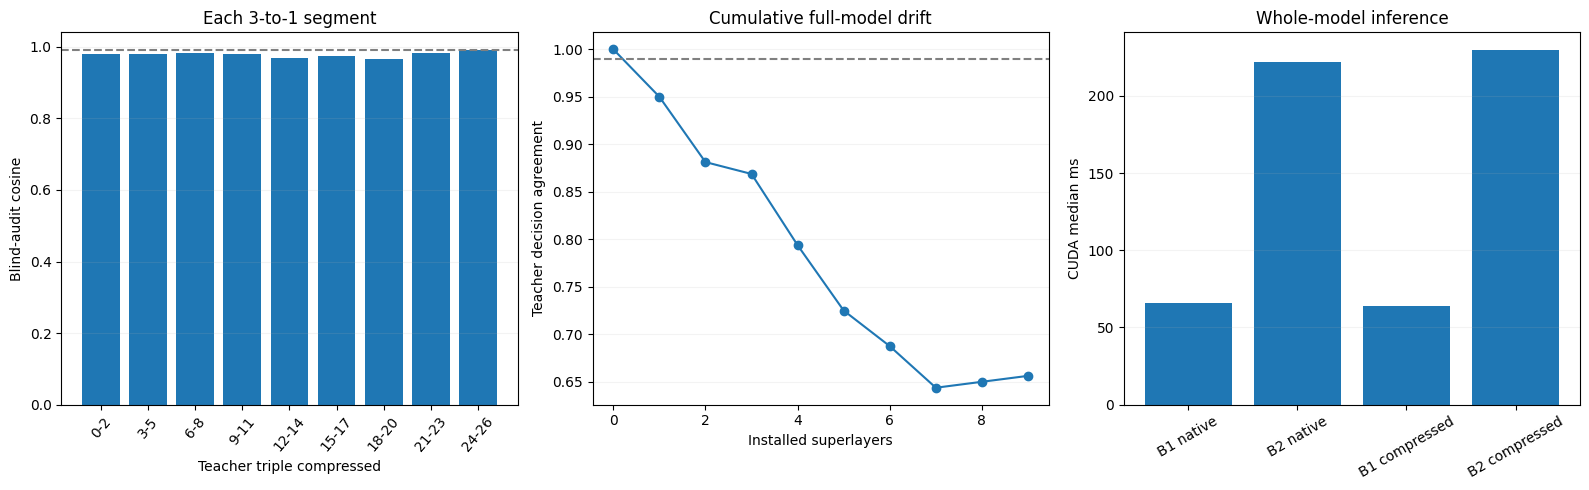

Figure: /content/Jev_CeNN_AllLayers_3to1/jev_cenn_all_groups_summary.png


In [14]:
#@title 14. Visualize per-group local fidelity, compounding task error and speed
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,3,figsize=(16,5))
labels=[f"{r['group'][0]}-{r['group'][2]}" for r in GROUP_REPORTS]
axes[0].bar(labels,[r["blind_audit_cenn_on"]["cosine"] for r in GROUP_REPORTS])
axes[0].axhline(0.99,ls="--",color="gray")
axes[0].set(xlabel="Teacher triple compressed",ylabel="Blind-audit cosine",
            title="Each 3-to-1 segment")
axes[1].plot(range(len(GROUP_REPORTS)+1),
             [ORIGINAL_BASELINE["agreement"]]+[
             r["cumulative_decision_quality"]["agreement"] for r in GROUP_REPORTS],
             marker="o")
axes[1].axhline(0.99,ls="--",color="gray")
axes[1].set(xlabel="Installed superlayers",ylabel="Teacher decision agreement",
            title="Cumulative full-model drift")
axes[2].bar([f"B{r['batch']} native" for r in PERF]+[
            f"B{r['batch']} compressed" for r in PERF],
            [r["original_ms"] for r in PERF]+[r["student_ms"] for r in PERF])
axes[2].set(ylabel="CUDA median ms",title="Whole-model inference")
for ax in axes:
    ax.grid(axis="y",alpha=.15)
axes[0].tick_params(axis="x",rotation=50)
axes[2].tick_params(axis="x",rotation=30)
fig.tight_layout()
image_file=OUTPUT_DIR/"jev_cenn_all_groups_summary.png"
fig.savefig(image_file,dpi=160,bbox_inches="tight")
plt.show()
print("Figure:",image_file)
